In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
SEASONS = [2023, 2024, 2025]
LAST_SEASON = max(SEASONS)
NULLS = ["NA", "NULL", "null", "None", ""]

DATA_DIR = Path("../data")
COMBINE_RESULTS = DATA_DIR / "combine_results.csv"
COMBINE_TRACKING = DATA_DIR / "combine_tracking.csv"
GAME_TRACKING_2023 = DATA_DIR / "game_tracking_2023.csv"
GAME_TRACKING_2024 = DATA_DIR / "game_tracking_2024.csv"
GAME_TRACKING_2025 = DATA_DIR / "game_tracking_2025.csv"
GAMES = DATA_DIR / "games.csv"
PLAYER_CAREER_SUCCESSES = DATA_DIR / "player_career_successes.csv"
PLAYER_PLAY = DATA_DIR / "player_play.csv"
PLAYERS = DATA_DIR / "players.csv"

def find_csv(stem):
    hits = sorted(DATA_DIR.rglob(f"{stem}.csv"))
    if not hits:
        raise FileNotFoundError(f"{stem}.csv not found under {DATA_DIR.resolve()}")
    return hits[0]

def pick(df, candidates, required=False):
    # Return the first column name in `candidates` that exists in df (case-insensitive).
    lower = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower:
            return lower[c.lower()]
    if required:
        raise KeyError(f"None of {candidates} in columns: {list(df.columns)}")
    return None

def overview(df, name):
    print(f"── {name}: {df.shape[0]:,} rows × {df.shape[1]} cols")
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "pct_null": (df.isna().mean() * 100).round(1),
        "n_unique": df.nunique(),
        "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })
    return out

In [3]:
COMBINE_RESULTS = DATA_DIR / "combine_results.csv"
COMBINE_TRACKING = DATA_DIR / "combine_tracking.csv"
GAME_TRACKING_2023 = DATA_DIR / "game_tracking_2023.csv"
GAME_TRACKING_2024 = DATA_DIR / "game_tracking_2024.csv"
GAME_TRACKING_2025 = DATA_DIR / "game_tracking_2025.csv"
GAMES = DATA_DIR / "games.csv"
PLAYER_CAREER_SUCCESSES = DATA_DIR / "player_career_successes.csv"
PLAYER_PLAY = DATA_DIR / "player_play.csv"
PLAYERS = DATA_DIR / "players.csv"

players  = pd.read_csv(find_csv("players"), na_values=NULLS)
combine  = pd.read_csv(find_csv("combine_results"), na_values=NULLS)
career   = pd.read_csv(find_csv("player_career_successes"), na_values=NULLS)
games    = pd.read_csv(find_csv("games"), na_values=NULLS)
pp       = pd.read_csv(find_csv("player_play"), na_values=NULLS, low_memory=False)

pp = pp.rename(columns={"visitor_team_win_probility_added": "visitor_team_win_probability_added"})

for df, n in [(players, "players"), (combine, "combine_results"), (career, "player_career_successes"),
              (games, "games"), (pp, "player_play")]:
    print(f"{n:26s} {df.shape[0]:>9,} rows  {df.shape[1]:>3} cols")

players                          510 rows   10 cols
combine_results                  510 rows   18 cols
player_career_successes          510 rows    9 cols
games                          1,002 rows    7 cols
player_play                  314,197 rows   64 cols


In [4]:
overview(players, 'players')

── players: 510 rows × 10 cols


,dtype,non_null,pct_null,n_unique,example
nfl_id,int64,510,0.0,510,55867
display_name,object,510,0.0,508,Will Anderson
draft_year,int64,510,0.0,3,2023
nfl_position,object,510,0.0,17,DE
birth_date,object,510,0.0,441,2001-09-02
college_name,object,510,0.0,112,Alabama
college_conference,object,510,0.0,21,Southeastern Conference
draft_round,float64,383,24.9,7,1.0
draft_pick_within_round,float64,383,24.9,42,3.0
draft_overall_pick,float64,383,24.9,222,3.0


In [5]:
overview(combine, 'combine_results')

── combine_results: 510 rows × 18 cols


,dtype,non_null,pct_null,n_unique,example
draft_year,int64,510,0.0,3,2023
nfl_id,int64,510,0.0,510,56040
combine_position,object,510,0.0,5,TE
combine_height,float64,510,0.0,95,77.875
combine_weight,int64,510,0.0,149,245
hand_size,float64,510,0.0,27,10.0
arm_length,float64,510,0.0,60,32.25
wing_span,float64,510,0.0,114,79.75
ten_yd_split,float64,425,16.7,46,1.6
forty,float64,424,16.9,106,4.84


In [6]:
overview(career, 'player_career_successes')

── player_career_successes: 510 rows × 9 cols


,dtype,non_null,pct_null,n_unique,example
nfl_id,int64,510,0.0,510,55867
career_offensive_snaps,int64,510,0.0,195,0
career_defensive_snaps,int64,510,0.0,183,1884
career_special_teams_snaps,int64,510,0.0,224,92
career_games_active,int64,510,0.0,51,51
career_games_started,int64,510,0.0,46,44
ap_all_pro_1st_team,int64,510,0.0,2,1
ap_all_pro_2nd_team,int64,510,0.0,2,0
pro_bowl_original_ballot,int64,510,0.0,3,1


In [7]:
overview(games, 'games')

── games: 1,002 rows × 7 cols


,dtype,non_null,pct_null,n_unique,example
game_id,int64,1002,0.0,1002,2023090700
game_key,int64,1002,0.0,1002,59173
season,int64,1002,0.0,3,2023
season_type,object,1002,0.0,3,REG
week,int64,1002,0.0,23,1
home_team_abbr,object,1002,0.0,33,KC
visitor_team_abbr,object,1002,0.0,33,DET


In [8]:
overview(pp, 'player_play') 

── player_play: 314,197 rows × 64 cols


,dtype,non_null,pct_null,n_unique,example
game_id,int64,314197,0.0,1001,2025111610
play_id,int64,314197,0.0,4931,2279
team_abbr,object,314197,0.0,33,BAL
nfl_id,int64,314197,0.0,497,57183
lined_up_position,object,312814,0.4,17,T
...,...,...,...,...,...
tackle_for_loss,object,11896,96.2,2,False
time_to_pressure,float64,3804,98.8,78,2.1
time_to_qb_hurry,float64,3879,98.8,79,2.1
coverage_assignment,object,72652,76.9,20,NO_ASSIGNMENT


In [9]:
# Build one wide player table: bio + combine + career
dup_cols = [c for c in combine.columns if c in players.columns and c != "nfl_id"]
prof = (players
        .merge(combine.drop(columns=dup_cols), on="nfl_id", how="left")
        .merge(career.drop(columns=[c for c in career.columns if c in players.columns and c != "nfl_id"]),
               on="nfl_id", how="left"))

NAME = pick(prof, ["display_name", "player_name", "full_name", "name"])
if NAME is None and {"first_name", "last_name"} <= set(prof.columns):
    prof["display_name"] = prof["first_name"] + " " + prof["last_name"]; NAME = "display_name"
NFL_POS  = pick(prof, ["nfl_position", "position"])
CMB_POS  = pick(prof, ["combine_position"])
DRAFT_YR = pick(prof, ["draft_year"], required=True)
ROUND    = pick(prof, ["draft_round"])
PICK     = pick(prof, ["draft_pick", "draft_overall_pick", "overall_pick", "draft_number"])
COLLEGE  = pick(prof, ["college_name", "college"])
CONF     = pick(prof, ["college_conference", "conference"])
print(dict(NAME=NAME, NFL_POS=NFL_POS, CMB_POS=CMB_POS, DRAFT_YR=DRAFT_YR,
           ROUND=ROUND, PICK=PICK, COLLEGE=COLLEGE, CONF=CONF))
prof.head()

{'NAME': 'display_name', 'NFL_POS': 'nfl_position', 'CMB_POS': 'combine_position', 'DRAFT_YR': 'draft_year', 'ROUND': 'draft_round', 'PICK': 'draft_overall_pick', 'COLLEGE': 'college_name', 'CONF': 'college_conference'}


,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1.0,3.0,3.0,DL,75.500,253,9.875,33.875,81.000,1.61,4.60,NaN,NaN,NaN,NaN,NaN,76,99.0,91.0,0,1884,92,51,44,1,0,1
1,55870,Paris Johnson,2023,T,2001-07-31,Ohio State,Big Ten Conference,1.0,6.0,6.0,OL,78.375,313,9.500,36.125,85.125,NaN,NaN,NaN,110.0,NaN,NaN,29.0,81,76.0,80.0,2802,0,169,47,43,0,0,0
2,55874,Darnell Wright,2023,T,2001-08-10,Tennessee,Southeastern Conference,1.0,10.0,10.0,OL,77.375,333,9.000,33.750,82.000,1.81,5.01,29.0,114.0,NaN,NaN,NaN,84,70.0,78.0,3222,0,167,51,49,0,1,0
3,55875,Peter Skoronski,2023,G,2001-07-31,Northwestern,Big Ten Conference,1.0,11.0,11.0,OL,76.000,313,10.000,32.250,79.500,1.75,5.16,34.5,115.0,7.80,NaN,30.0,84,93.0,89.0,3011,0,170,51,48,0,0,0
4,55877,Lukas Van Ness,2023,DE,2001-07-06,Iowa,Big Ten Conference,1.0,13.0,13.0,DL,77.000,272,11.000,34.000,81.750,1.64,4.58,31.0,118.0,7.02,4.32,17.0,77,74.0,80.0,0,1056,387,51,2,0,0,0


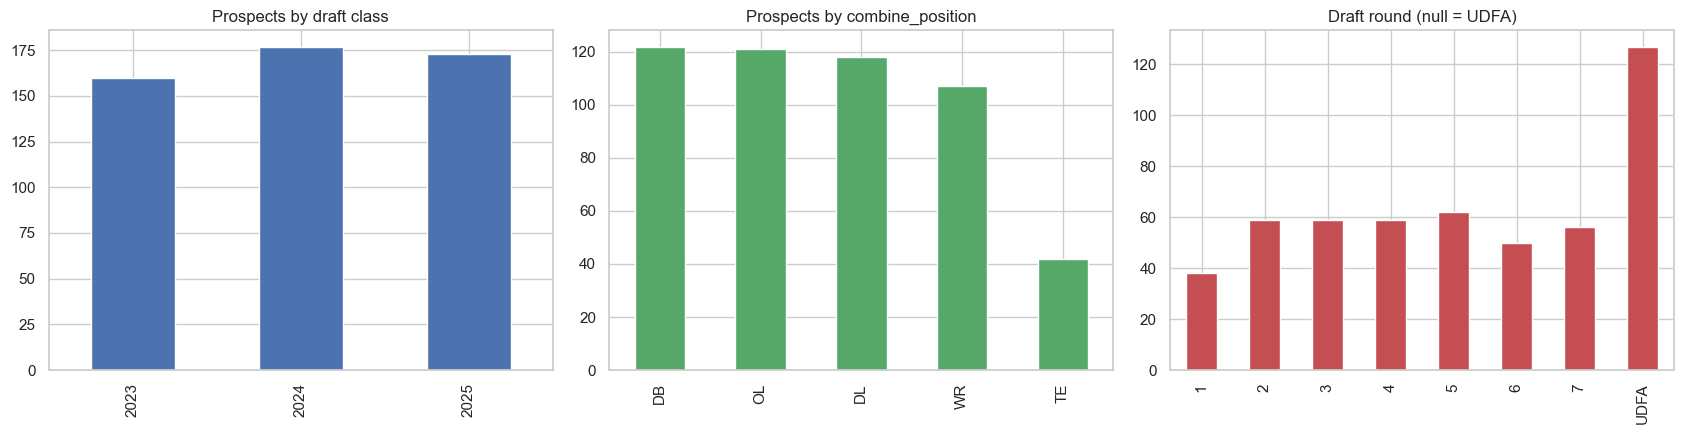

nfl_position,C,CB,DB,DE,DT,FB,FS,G,ILB,MLB,NT,OLB,RB,SS,T,TE,WR,All
combine_position,,,,,,,,,,,,,,,,,,
DB,0,60,5,0,0,0,25,0,2,1,0,0,1,28,0,0,0,122
DL,0,0,0,36,47,0,0,0,0,0,5,30,0,0,0,0,0,118
OL,20,0,0,0,0,0,0,51,0,0,0,0,0,0,50,0,0,121
TE,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,41,0,42
WR,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,106,107
All,20,60,5,36,47,1,25,51,2,1,5,30,1,28,50,42,106,510


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

prof[DRAFT_YR].value_counts().sort_index().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Prospects by draft class"); axes[0].set_xlabel("")

pos_col = CMB_POS or NFL_POS
prof[pos_col].value_counts().plot.bar(ax=axes[1], color="#55A868")
axes[1].set_title(f"Prospects by {pos_col}"); axes[1].set_xlabel("")

if ROUND:
    rnd = prof[ROUND].fillna(0).astype(int).replace(0, "UDFA").astype(str)
    order = [str(i) for i in range(1, 8)] + ["UDFA"]
    rnd.value_counts().reindex(order).fillna(0).plot.bar(ax=axes[2], color="#C44E52")
    axes[2].set_title("Draft round (null = UDFA)"); axes[2].set_xlabel("")
plt.tight_layout(); plt.show()

if CMB_POS and NFL_POS:
    display(pd.crosstab(prof[CMB_POS], prof[NFL_POS], margins=True))

In [11]:
OL_LABELS = {"OL", "OT", "OG", "IOL", "C", "G", "T", "LT", "RT", "LG", "RG", "OC"}

def to_group(p):
    if pd.isna(p): return np.nan
    p = str(p).upper().strip()
    if p in {"C", "OC"}: return "C"
    if p in {"G", "OG", "LG", "RG"}: return "G"
    if p in {"T", "OT", "LT", "RT"}: return "T"
    if p in {"OL", "IOL"}: return p  # ambiguous, resolved below
    return np.nan

is_ol = pd.Series(False, index=prof.index)
for c in [CMB_POS, NFL_POS]:
    if c: is_ol |= prof[c].astype(str).str.upper().isin(OL_LABELS)
ol = prof[is_ol].copy()
ol["listed_group"] = ol[NFL_POS].map(to_group) if NFL_POS else np.nan
if CMB_POS:
    ol["listed_group"] = ol["listed_group"].fillna(ol[CMB_POS].map(to_group))
print(f"Offensive linemen: {len(ol)} of {len(prof)} prospects")
ol["listed_group"].value_counts(dropna=False)

Offensive linemen: 121 of 510 prospects


listed_group
G    51
T    50
C    20
Name: count, dtype: int64

In [12]:
LUP = pick(pp, ["lined_up_position", "position_at_snap"])
print("lined-up column:", LUP)
print(pp.loc[pp["nfl_id"].isin(ol["nfl_id"]), LUP].value_counts(dropna=False).head(20))

lined-up column: lined_up_position
lined_up_position
G              48507
T              42849
C              14959
TE               784
NaN              542
FB                46
SLOT_WR           15
HIGH_SAFETY       10
WR                 3
OLB                3
EXTRA_OL           1
CB                 1
Name: count, dtype: int64


In [13]:
ol_pp = pp[pp["nfl_id"].isin(ol["nfl_id"])].copy()
ol_pp["lup_group"] = ol_pp[LUP].map(to_group)
ol_pp = ol_pp.merge(games[["game_id", "season", "week"] +
                          [c for c in ["season_type"] if c in games.columns]],
                    on="game_id", how="left")

share = (ol_pp.dropna(subset=["lup_group"])
              .groupby(["nfl_id", "lup_group"]).size()
              .unstack(fill_value=0))
for g in ["C", "G", "T"]:
    if g not in share: share[g] = 0
share["snaps_at_ol"] = share[["C", "G", "T"]].sum(axis=1)
for g in ["C", "G", "T"]:
    share[f"pct_{g}"] = (share[g] / share["snaps_at_ol"]).round(3)
share["played_group"] = share[["C", "G", "T"]].idxmax(axis=1)
share["primary_pct"] = share[["pct_C", "pct_G", "pct_T"]].max(axis=1)

ol = ol.merge(share[["snaps_at_ol", "pct_C", "pct_G", "pct_T", "played_group", "primary_pct"]],
              left_on="nfl_id", right_index=True, how="left")
ol["snaps_at_ol"] = ol["snaps_at_ol"].fillna(0).astype(int)

# Final label: where he actually played if he has meaningful snaps, else the listed position
MIN_SNAPS_FOR_PLAYED = 50
ol["pos_group"] = np.where(ol["snaps_at_ol"] >= MIN_SNAPS_FOR_PLAYED, ol["played_group"], ol["listed_group"])

print("Listed vs. played (players with any OL snaps):")
display(pd.crosstab(ol["listed_group"].fillna("?"), ol["played_group"].fillna("no snaps"), margins=True))
print("\nFinal pos_group:")
display(ol["pos_group"].value_counts(dropna=False))

Listed vs. played (players with any OL snaps):


played_group,C,G,T,no snaps,All
listed_group,,,,,
C,17,3,0,0,20
G,2,45,3,1,51
T,0,8,42,0,50
All,19,56,45,1,121



Final pos_group:


pos_group
G    56
T    47
C    18
Name: count, dtype: int64

In [14]:
swing = ol[(ol["snaps_at_ol"] >= MIN_SNAPS_FOR_PLAYED) & (ol["primary_pct"] < 0.8)]
print(f"Swing players (<80% of snaps at one spot, ≥{MIN_SNAPS_FOR_PLAYED} snaps): {len(swing)}")
swing[[NAME, DRAFT_YR, "listed_group", "snaps_at_ol", "pct_C", "pct_G", "pct_T"]].sort_values("snaps_at_ol", ascending=False)

Swing players (<80% of snaps at one spot, ≥50 snaps): 16


,display_name,draft_year,listed_group,snaps_at_ol,pct_C,pct_G,pct_T
31,Juice Scruggs,2023,G,1991,0.330,0.670,0.000
94,Jarrett Patterson,2023,C,1888,0.794,0.206,0.000
184,Jackson Powers-Johnson,2024,G,1373,0.306,0.693,0.001
80,Asim Richards,2023,T,1048,0.000,0.210,0.790
357,Anthony Belton,2025,T,701,0.000,0.662,0.338
60,Jon Gaines,2023,C,532,0.256,0.744,0.000
46,Ricky Stromberg,2023,C,379,0.475,0.525,0.000
483,Torricelli Simpkins,2025,G,335,0.466,0.531,0.003
104,Nick Broeker,2023,G,327,0.000,0.431,0.569
252,Jacob Monk,2024,C,280,0.561,0.439,0.000


In [15]:
ol["seasons_available"] = LAST_SEASON - ol[DRAFT_YR] + 1

ps = (ol_pp.groupby(["nfl_id", "season"])
           .agg(plays=("play_id", "size"), games=("game_id", "nunique"))
           .reset_index())
ps["season_of_career"] = ps["season"] - ps["nfl_id"].map(ol.set_index("nfl_id")[DRAFT_YR]) + 1

obs = ps.groupby("nfl_id").agg(seasons_observed=("season", "nunique"),
                               total_plays=("plays", "sum"), total_games=("games", "sum"))
ol = ol.drop(columns=[c for c in obs.columns if c in ol.columns]).merge(obs, left_on="nfl_id", right_index=True, how="left")
ol[["seasons_observed", "total_plays", "total_games"]] = ol[["seasons_observed", "total_plays", "total_games"]].fillna(0).astype(int)

display(pd.crosstab([ol[DRAFT_YR]], ol["seasons_observed"], margins=True)
          .rename_axis(index="draft class", columns="seasons observed"))
display(pd.crosstab(ol["pos_group"], ol["seasons_observed"], margins=True))

seasons observed,0,1,2,3,All
draft class,,,,,
2023,0,2,5,30,37
2024,0,9,37,0,46
2025,1,37,0,0,38
All,1,48,42,30,121


seasons_observed,0,1,2,3,All
pos_group,,,,,
C,0,6,8,4,18
G,1,23,18,14,56
T,0,19,16,12,47
All,1,48,42,30,121


In [16]:
# Player × season grid of plays (sorted by class, then total plays)
grid = ps.pivot(index="nfl_id", columns="season", values="plays").reindex(columns=SEASONS)
meta = ol.set_index("nfl_id")[[NAME, DRAFT_YR, "pos_group", "total_plays"]]
grid = meta.join(grid, how="left").sort_values([DRAFT_YR, "total_plays"], ascending=[True, False])
grid.head(40)

,display_name,draft_year,pos_group,total_plays,2023,2024,2025
nfl_id,,,,,,,
55924,O'Cyrus Torrence,2023,G,3942,1389.0,1264.0,1289.0
55874,Darnell Wright,2023,T,3477,1135.0,1064.0,1278.0
55891,Anton Harrison,2023,T,3180,1161.0,977.0,1042.0
55903,Matthew Bergeron,2023,G,3170,1153.0,1105.0,912.0
55875,Peter Skoronski,2023,G,3164,919.0,1145.0,1100.0
55901,Steve Avila,2023,G,3016,1242.0,723.0,1051.0
55878,Broderick Jones,2023,T,2863,976.0,1213.0,674.0
55870,Paris Johnson,2023,T,2850,1160.0,865.0,825.0
55913,Cody Mauch,2023,G,2696,1328.0,1210.0,158.0


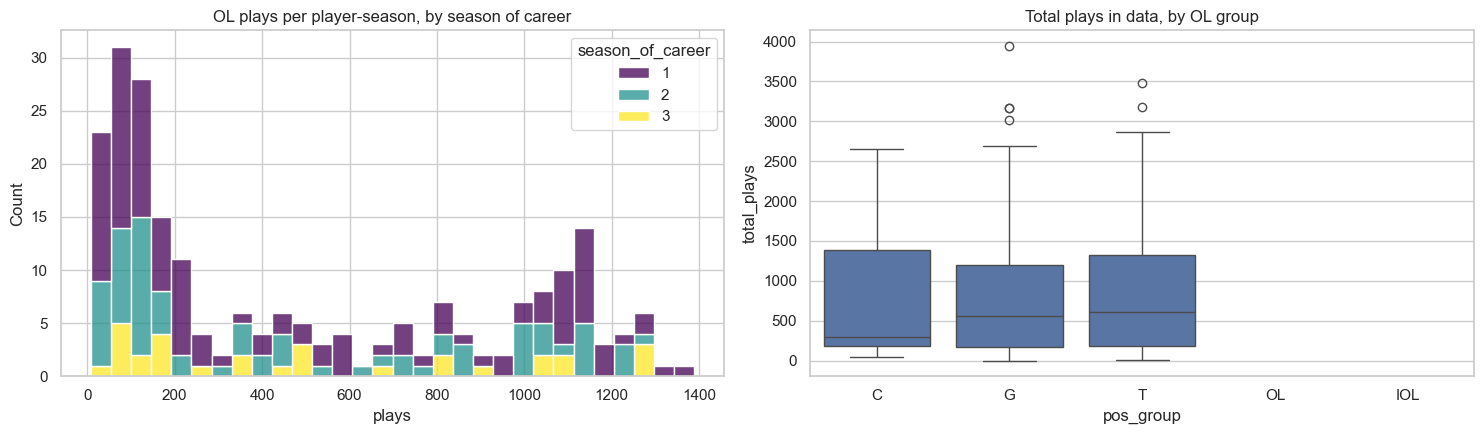

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(ps, x="plays", hue="season_of_career", multiple="stack", bins=30, ax=axes[0], palette="viridis")
axes[0].set_title("OL plays per player-season, by season of career")
sns.boxplot(data=ol, x="pos_group", y="total_plays", order=["C", "G", "T", "OL", "IOL"], ax=axes[1])
axes[1].set_title("Total plays in data, by OL group")
plt.tight_layout(); plt.show()

In [18]:
TESTS = [c for c in ["combine_height", "combine_weight", "arm_length", "hand_size", "wingspan",
                     "ten_yd_split", "forty", "vertical", "broad_jump", "three_cone",
                     "short_shuttle", "bench_reps"] if c in ol.columns]
GRADE_COLS = [c for c in ol.columns if "grade" in c.lower() or "score" in c.lower()]
print("Tests:", TESTS); print("Grade/score cols:", GRADE_COLS)

summary = ol.groupby("pos_group")[TESTS].agg(["count", "mean"]).round(2)
summary

Tests: ['combine_height', 'combine_weight', 'arm_length', 'hand_size', 'ten_yd_split', 'forty', 'vertical', 'broad_jump', 'three_cone', 'short_shuttle', 'bench_reps']
Grade/score cols: ['ngs_athleticism_score', 'ngs_college_production_score', 'ngs_final_score']


combine_height        combine_weight         arm_length        hand_size        ten_yd_split       forty       vertical        broad_jump         three_cone       short_shuttle        \
                   count   mean          count    mean      count   mean     count   mean        count  mean count  mean    count   mean      count    mean      count  mean         count  mean   
pos_group                                                                                                                                                                                          
C                     18  75.57             18  304.33         18  31.94        18   9.63           15  1.77    15  5.14       14  30.64         14  108.50         13  7.56            14  4.57   
G                     56  76.46             56  314.14         56  33.12        56   9.97           43  1.79    43  5.17       50  30.04         49  107.43         27  7.70            29  4.69   
T                     47  78.13             47  318.74         47  34.07        47  10.08           38  1.78    37  5.14       36  30.03         35  108.49         21  7.71            21  4.75   

          bench_reps         
               count   mean  
pos_group                    
C                 11  26.45  
G                 25  26.56  
T                 17  25.88

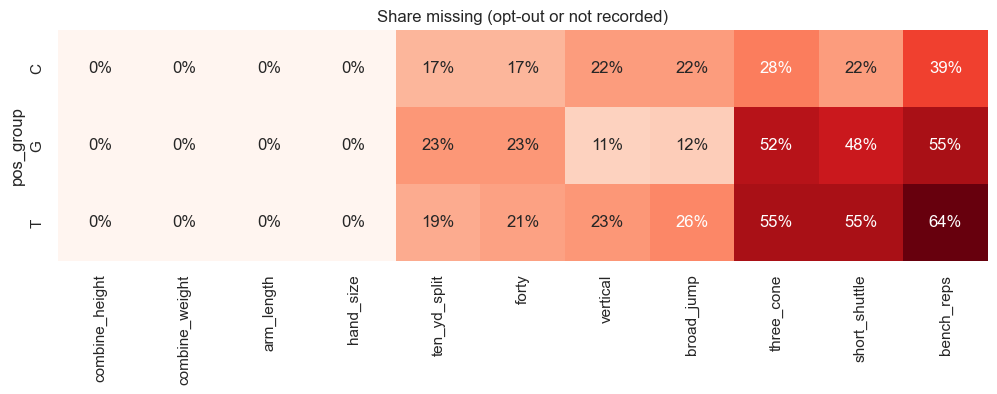

In [19]:
# Opt-out / missingness rate by test and position (matters: opt-outs are not random)
optout = ol.groupby("pos_group")[TESTS].apply(lambda d: d.isna().mean()).round(2)
plt.figure(figsize=(12, 3))
sns.heatmap(optout, annot=True, fmt=".0%", cmap="Reds", cbar=False)
plt.title("Share missing (opt-out or not recorded)"); plt.show()

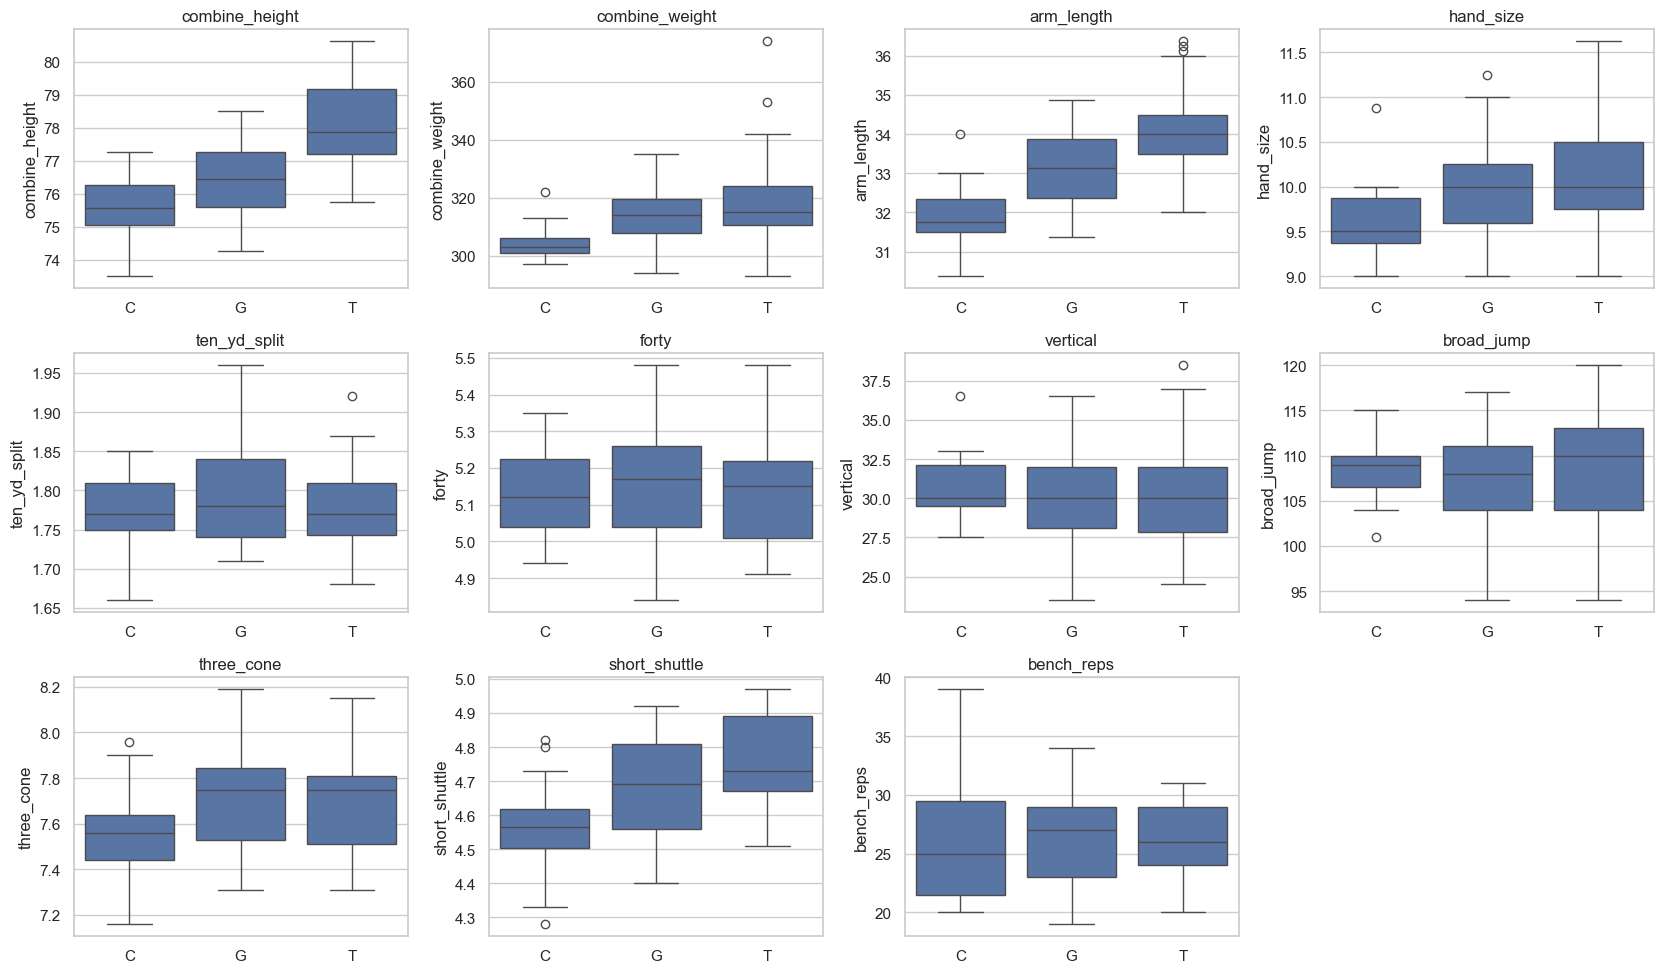

In [20]:
plot_tests = [t for t in TESTS if ol[t].notna().sum() > 10]
n = len(plot_tests); cols = 4; rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.3 * rows))
for ax, t in zip(axes.flat, plot_tests):
    sns.boxplot(data=ol, x="pos_group", y=t, order=[g for g in ["C", "G", "T"] if g in set(ol["pos_group"])], ax=ax)
    ax.set_xlabel(""); ax.set_title(t)
for ax in axes.flat[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

In [21]:
DRILL_FIXES = {
    "PASS_PRO-MIRROR_DRILL": "PASS_PRO_MIRROR_DRILL",
    "OVER_SHOULDER_ADJUST": "OVER_THE_SHOULDER_ADJUST",
    "LINE": "LINE_DRILL",
    "SPEED_OUT_LEFT": "SPEED_OUT_ROUTE_LEFT",
    "SPEED_OUT_RIGHT": "SPEED_OUT_ROUTE_RIGHT",
}
ct = pd.read_csv(find_csv("combine_tracking"), na_values=NULLS)
print("combine_tracking:", ct.shape, list(ct.columns))
if "entity_type" in ct: ct = ct[ct["entity_type"] == "PLAYER"]
ct["drill_name_raw"] = ct["drill_name"]
ct["drill_name"] = ct["drill_name"].replace(DRILL_FIXES)

ol_ct = ct[ct["nfl_id"].isin(ol["nfl_id"])].copy()
ol_ct = ol_ct.merge(ol[["nfl_id", "pos_group"]], on="nfl_id", how="left")
print(f"OL tracking rows: {len(ol_ct):,} | OL players with any tracking: {ol_ct['nfl_id'].nunique()} of {len(ol)}")

combine_tracking: (463189, 14) ['draft_year', 'event_id', 'nfl_id', 'entity_type', 'time', 'drill_type', 'drill_name', 'attempt', 'x', 'y', 's', 'a', 'dis', 'dir']
OL tracking rows: 79,100 | OL players with any tracking: 121 of 121


In [22]:
attempt_key = ["event_id", "nfl_id"]
att = ol_ct.drop_duplicates(attempt_key)
catalog = (att.groupby(["drill_type", "drill_name"])
              .agg(attempts=("event_id", "size"), players=("nfl_id", "nunique"),
                   years=("draft_year", lambda s: sorted(s.unique())) if "draft_year" in att else ("nfl_id", "size"))
              .sort_values("players", ascending=False))
catalog

attempts  players               years
drill_type       drill_name                                                                   
SKILL_DRILLS_OL  PASS_PRO_MIRROR_DRILL                        121      121  [2023, 2024, 2025]
                 FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE       120      120  [2023, 2024, 2025]
                 PASS_RUSH_DROP                               239      120  [2023, 2024, 2025]
                 OL_PULL_DRILL_FOLD_BLOCK_RIGHT               119      119  [2023, 2024, 2025]
                 SCREEN_DRILL                                 120      119  [2023, 2024, 2025]
                 OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT            98       98  [2023, 2024, 2025]
FORTY_YARD_DASH  FORTY_YARD_DASH                              179       95  [2023, 2024, 2025]
SKILL_DRILLS_OL  OL_PULL_DRILL_LONG_PULL_RIGHT                 93       93  [2023, 2024, 2025]
SHORT_SHUTTLE    SHORT_SHUTTLE                                 70       54  [2023, 2024, 2025]
THREE_CONE_DRILL THREE_CONE_DRILL                              55       48  [2023, 2024, 2025]

In [23]:
# Drill coverage by position group: how many C / G / T have each drill?
cov = (att.groupby(["drill_name", "pos_group"])["nfl_id"].nunique()
          .unstack(fill_value=0))
cov = cov[[g for g in ["C", "G", "T", "OL", "IOL"] if g in cov]]
cov["total"] = cov.sum(axis=1)
cov.sort_values("total", ascending=False)

pos_group,C,G,T,total
drill_name,,,,
PASS_PRO_MIRROR_DRILL,18,56,47,121
FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,18,55,47,120
PASS_RUSH_DROP,18,55,47,120
OL_PULL_DRILL_FOLD_BLOCK_RIGHT,18,55,46,119
SCREEN_DRILL,18,56,45,119
OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT,15,47,36,98
FORTY_YARD_DASH,15,43,37,95
OL_PULL_DRILL_LONG_PULL_RIGHT,13,45,35,93
SHORT_SHUTTLE,12,25,17,54


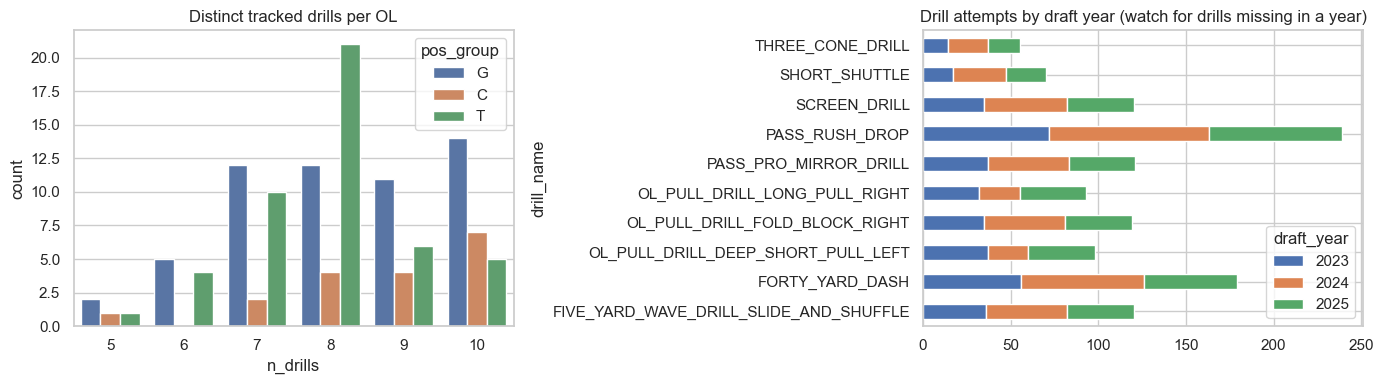

In [24]:
# Per-player: number of distinct drills and attempts, plus which drills per draft year
per_player = att.groupby("nfl_id").agg(n_drills=("drill_name", "nunique"), n_attempts=("event_id", "size"))
ol = ol.drop(columns=[c for c in per_player.columns if c in ol.columns]).merge(per_player, left_on="nfl_id", right_index=True, how="left")
ol[["n_drills", "n_attempts"]] = ol[["n_drills", "n_attempts"]].fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=ol, x="n_drills", hue="pos_group", ax=axes[0]); axes[0].set_title("Distinct tracked drills per OL")
if "draft_year" in att:
    pd.crosstab(att["drill_name"], att["draft_year"]).plot.barh(ax=axes[1], stacked=True, figsize=None)
    axes[1].set_title("Drill attempts by draft year (watch for drills missing in a year)")
plt.tight_layout(); plt.show()

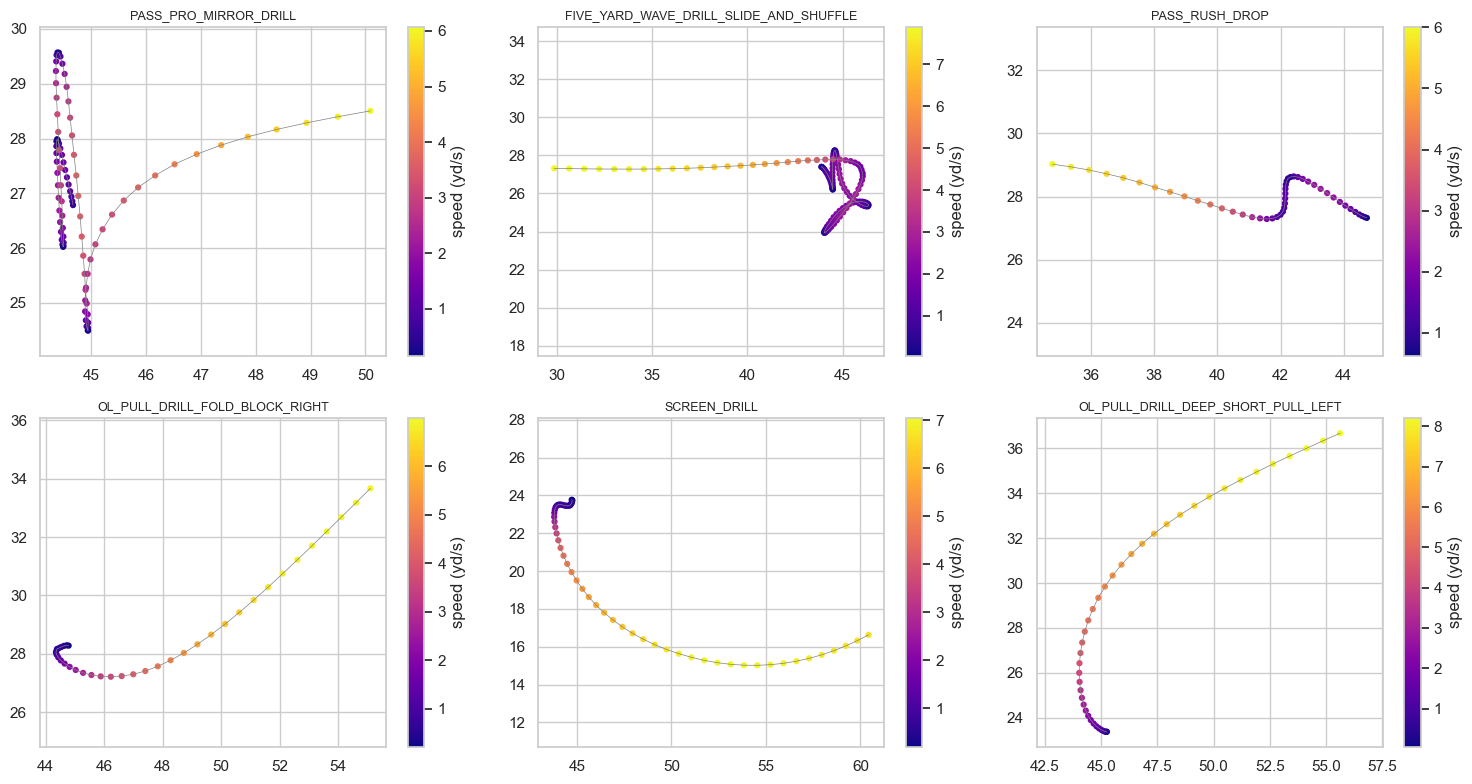

In [25]:
# Look at one rep of each of the most common OL drills, to see what the raw tracking looks like
top_drills = catalog.reset_index().query("drill_type != 'FORTY_YARD_DASH'")["drill_name"].head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, d in zip(axes.flat, top_drills):
    ev = att.loc[att["drill_name"] == d, "event_id"].iloc[0]
    rep = ol_ct[(ol_ct["event_id"] == ev)].sort_values("time")
    sc = ax.scatter(rep["x"], rep["y"], c=rep["s"], cmap="plasma", s=12)
    ax.plot(rep["x"], rep["y"], lw=0.5, color="grey")
    ax.set_title(d, fontsize=9); ax.set_aspect("equal", adjustable="datalim")
    plt.colorbar(sc, ax=ax, label="speed (yd/s)")
for ax in axes.flat[len(top_drills):]: ax.axis("off")
plt.tight_layout(); plt.show()

In [26]:
CAREER_COLS = [c for c in career.columns if c != "nfl_id"]
print("Career columns:", CAREER_COLS)
display(ol.groupby("pos_group")[[c for c in CAREER_COLS if pd.api.types.is_numeric_dtype(ol[c])]]
          .agg(["mean", "median", "max"]).round(1).T)

Career columns: ['career_offensive_snaps', 'career_defensive_snaps', 'career_special_teams_snaps', 'career_games_active', 'career_games_started', 'ap_all_pro_1st_team', 'ap_all_pro_2nd_team', 'pro_bowl_original_ballot']


pos_group                               C       G       T
career_offensive_snaps     mean     597.4   718.4   757.4
                           median    77.5   358.0   427.0
                           max     2526.0  3303.0  3222.0
career_defensive_snaps     mean       0.0     0.0     0.0
                           median     0.0     0.0     0.0
                           max        0.0     0.0     0.0
career_special_teams_snaps mean      45.2    67.2    62.0
                           median    35.0    52.5    50.0
                           max      131.0   248.0   183.0
career_games_active        mean      23.4    20.0    21.4
                           median    28.5    17.0    17.0
                           max       49.0    51.0    51.0
career_games_started       mean       9.3    10.9    11.7
                           median     1.0     6.0     5.0
                           max       41.0    50.0    49.0
ap_all_pro_1st_team        mean       0.0     0.0     0.0
                           median     0.0     0.0     0.0
                           max        0.0     0.0     0.0
ap_all_pro_2nd_team        mean       0.0     0.0     0.0
                           median     0.0     0.0     0.0
                           max        0.0     0.0     1.0
pro_bowl_original_ballot   mean       0.0     0.0     0.0
                           median     0.0     0.0     0.0
                           max        0.0     0.0     1.0

In [27]:
OL_METRICS = [c for c in pp.columns if any(k in c.lower() for k in
              ["pressure_allowed", "sack_allowed", "time_to_pressure_allowed",
               "peak_pressure_probability", "pass_rushers_encountered", "hit_allowed", "hurry_allowed"])]
print("OL pass-pro columns:", OL_METRICS)
display(ol_pp[OL_METRICS].describe(include="all").T)

OL pass-pro columns: ['extended_sack_allowed', 'pass_rushers_encountered', 'peak_pressure_probability_allowed', 'pressure_allowed', 'sack_allowed', 'time_to_pressure_allowed']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
extended_sack_allowed,60186.0,NaN,NaN,NaN,0.00172,0.03964,0.0,0.0,0.0,0.0,1.0
pass_rushers_encountered,60186.0,NaN,NaN,NaN,0.982621,0.260234,0.0,1.0,1.0,1.0,3.0
peak_pressure_probability_allowed,57618.0,NaN,NaN,NaN,0.277937,0.239132,0.0,0.130833,0.183333,0.3075,1.0
pressure_allowed,60186,2,False,55255,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sack_allowed,60186.0,NaN,NaN,NaN,0.009678,0.094732,0.0,0.0,0.0,0.0,1.0
time_to_pressure_allowed,4927.0,NaN,NaN,NaN,3.025675,1.035912,0.9,2.3,2.8,3.4,10.7


In [28]:
# Pass-pro rates per player-season (only plays where a pass-pro metric is recorded)
pp_flag = pick(ol_pp, ["pressure_allowed"])
sack_flag = pick(ol_pp, ["sack_allowed"])
peak = pick(ol_pp, ["peak_pressure_probability_allowed"])

pb = ol_pp[ol_pp[pp_flag].notna()].copy() if pp_flag else ol_pp.iloc[0:0]
for c in [pp_flag, sack_flag]:
    if c and pb[c].dtype == object:
        pb[c] = pb[c].astype(str).str.lower().isin(["true", "1", "y"])
agg = {"pass_blocks": ("play_id", "size")}
if pp_flag:   agg["pressure_rate"] = (pp_flag, "mean")
if sack_flag: agg["sack_rate"] = (sack_flag, "mean")
if peak:      agg["mean_peak_pressure_prob"] = (peak, "mean")
pass_pro = pb.groupby(["nfl_id", "season"]).agg(**agg).reset_index()
pass_pro = pass_pro.merge(ol[["nfl_id", NAME, "pos_group", DRAFT_YR]], on="nfl_id")

for thr in [0, 50, 100, 200, 400]:
    n = pass_pro[pass_pro["pass_blocks"] >= thr].groupby("pos_group")["nfl_id"].nunique()
    print(f"more than {thr:3d} pass blocks in a season:", n.to_dict())

more than   0 pass blocks in a season: {'C': 18, 'G': 55, 'T': 47}
more than  50 pass blocks in a season: {'C': 14, 'G': 46, 'T': 39}
more than 100 pass blocks in a season: {'C': 9, 'G': 37, 'T': 30}
more than 200 pass blocks in a season: {'C': 7, 'G': 30, 'T': 26}
more than 400 pass blocks in a season: {'C': 6, 'G': 21, 'T': 20}


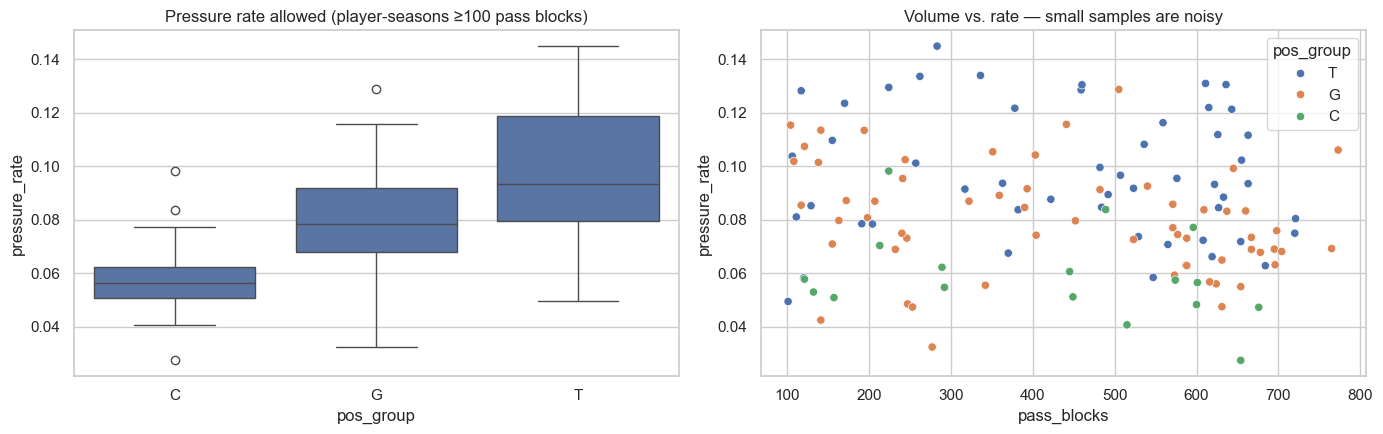

,nfl_id,season,pass_blocks,pressure_rate,sack_rate,mean_peak_pressure_prob,display_name,pos_group,draft_year
115,57172,2025,654,0.027523,0.003058,0.200273,Zach Frazier,C,2024
87,56450,2025,277,0.032491,0.000000,0.201346,T.J. Bass,G,2023
69,56066,2024,515,0.040777,0.003883,0.225896,Jarrett Patterson,C,2023
61,56021,2025,141,0.042553,0.000000,0.232552,Jordan McFadden,G,2023
126,57194,2024,676,0.047337,0.005917,0.212355,Cooper Beebe,C,2024
86,56450,2024,253,0.047431,0.003953,0.213535,T.J. Bass,G,2023
196,58262,2025,631,0.047544,0.004754,0.249235,Tate Ratledge,G,2025
114,57172,2024,600,0.048333,0.005833,0.220248,Zach Frazier,C,2024
85,56450,2023,247,0.048583,0.004049,0.224228,T.J. Bass,G,2023
75,56095,2024,101,0.049505,0.009901,0.272987,Nick Broeker,T,2023


In [29]:
qual = pass_pro[pass_pro["pass_blocks"] >= 100]
if len(qual) and "pressure_rate" in qual:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    sns.boxplot(data=qual, x="pos_group", y="pressure_rate", order=["C", "G", "T"], ax=axes[0])
    axes[0].set_title("Pressure rate allowed (player-seasons ≥100 pass blocks)")
    sns.scatterplot(data=qual, x="pass_blocks", y="pressure_rate", hue="pos_group", ax=axes[1])
    axes[1].set_title("Volume vs. rate — small samples are noisy")
    plt.tight_layout(); plt.show()
qual.sort_values("pressure_rate").head(15)

In [30]:
TEAM = pick(ol_pp, ["team_abbr", "club", "team"])
# Team schedule: every (season, week, team) game, from games.csv
home, away = pick(games, ["home_team_abbr"]), pick(games, ["visitor_team_abbr", "away_team_abbr"])
sched = pd.concat([games[["game_id", "season", "week", home]].rename(columns={home: "team"}),
                   games[["game_id", "season", "week", away]].rename(columns={away: "team"})])
if "season_type" in games:
    sched = sched.merge(games[["game_id", "season_type"]], on="game_id")
    sched = sched[sched["season_type"] == "REG"]

# Per player-game snaps, plus the team he was on that season (most common)
pg = (ol_pp.groupby(["nfl_id", "season", "week", "game_id"])
           .agg(snaps=("play_id", "size"), team=(TEAM, "first")).reset_index())
pteam = pg.groupby(["nfl_id", "season"])["team"].agg(lambda s: s.mode().iloc[0]).rename("team").reset_index()

# Expand each player-season to his team's full schedule, flag zero-snap games
full = pteam.merge(sched, on=["season", "team"], how="left")
full = full.merge(pg[["nfl_id", "game_id", "snaps"]], on=["nfl_id", "game_id"], how="left")
full["snaps"] = full["snaps"].fillna(0)
full = full.sort_values(["nfl_id", "season", "week"])

# "Established" = he has already had a game with ≥ 30 snaps earlier in that season
full["established"] = (full.assign(big=full["snaps"] >= 30)
                           .groupby(["nfl_id", "season"])["big"].transform(lambda s: s.shift(fill_value=False).cummax()))
full["missed_after_established"] = full["established"] & (full["snaps"] == 0)

avail = (full.groupby(["nfl_id", "season"])
             .agg(team_games=("game_id", "nunique"), games_played=("snaps", lambda s: (s > 0).sum()),
                  missed_after_est=("missed_after_established", "sum"))
             .reset_index())
avail["availability"] = (avail["games_played"] / avail["team_games"]).round(2)
avail = avail.merge(ol[["nfl_id", NAME, "pos_group"]], on="nfl_id")
avail.sort_values("missed_after_est", ascending=False).head(20)

,nfl_id,season,team_games,games_played,missed_after_est,availability,display_name,pos_group
108,57141,2024,17,1,15,0.06,Troy Fautanu,T
23,55913,2025,17,2,15,0.12,Cody Mauch,G
158,57337,2025,17,3,14,0.18,Beaux Limmer,C
49,55976,2025,17,3,14,0.18,Dawand Jones,T
93,56572,2025,17,2,14,0.12,John Ojukwu,T
220,58987,2025,17,4,11,0.24,Torricelli Simpkins,G
124,57189,2024,17,6,11,0.35,Caedan Wallace,T
218,58946,2025,17,3,11,0.18,Joe Huber,G
103,57126,2025,17,6,11,0.35,Joe Alt,T
68,56066,2023,17,7,10,0.41,Jarrett Patterson,C


Player-games flagged as possible in-game exits: 464


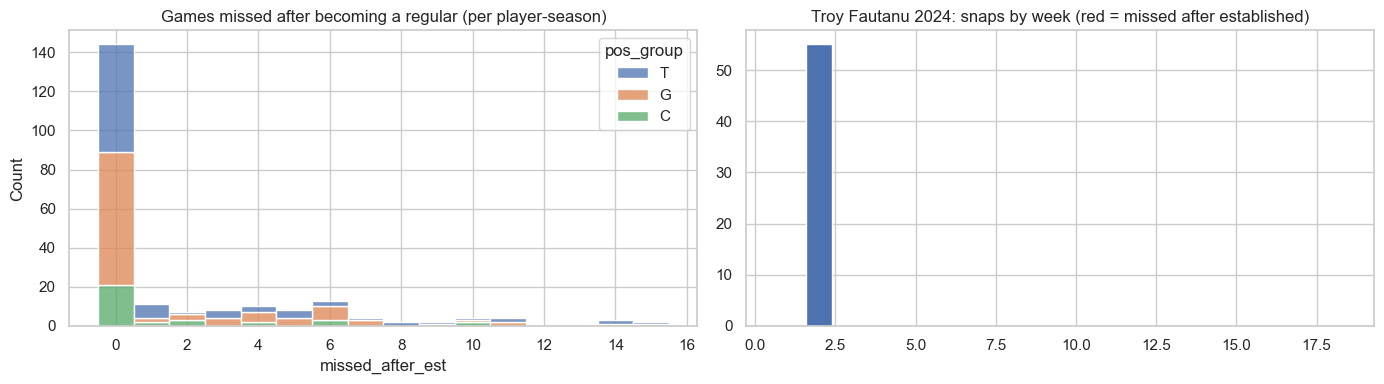

In [31]:
# Possible in-game exits: played ≥ 20 snaps, but < 50% of his own median snaps in established games
med = pg[pg["snaps"] >= 30].groupby(["nfl_id", "season"])["snaps"].median().rename("median_snaps")
pg2 = pg.merge(med, on=["nfl_id", "season"], how="inner")
pg2["possible_exit"] = (pg2["snaps"] < 0.5 * pg2["median_snaps"]) & (pg2["snaps"] > 0)
print("Player-games flagged as possible in-game exits:", int(pg2["possible_exit"].sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(avail, x="missed_after_est", hue="pos_group", multiple="stack", discrete=True, ax=axes[0])
axes[0].set_title("Games missed after becoming a regular (per player-season)")
# Example timeline for the player with the most such misses
ex = avail.sort_values("missed_after_est", ascending=False).iloc[0]
t = full[(full["nfl_id"] == ex["nfl_id"]) & (full["season"] == ex["season"])]
axes[1].bar(t["week"], t["snaps"], color=np.where(t["missed_after_established"], "#C44E52", "#4C72B0"))
axes[1].set_title(f"{ex[NAME]} {int(ex['season'])}: snaps by week (red = missed after established)")
plt.tight_layout(); plt.show()

In [32]:
SEASON_TO_PEEK = 2024
ol_ids = set(ol["nfl_id"])
chunks = []
for ch in pd.read_csv(find_csv(f"game_tracking_{SEASON_TO_PEEK}"), chunksize=2_000_000, na_values=NULLS):
    chunks.append(ch[ch["nfl_id"].isin(ol_ids)])
gt = pd.concat(chunks, ignore_index=True); del chunks
print(f"OL tracking rows {SEASON_TO_PEEK}: {len(gt):,}  | columns: {list(gt.columns)}")
print("Events:", gt["event"].value_counts().head(10).to_dict() if "event" in gt else "n/a")

trk = gt.groupby("nfl_id").agg(tracked_plays=("play_id", lambda s: s.nunique()))
trk = trk.join(ol.set_index("nfl_id")[[NAME, "pos_group"]])
trk.sort_values("tracked_plays", ascending=False).head(15)

OL tracking rows 2024: 2,553,789  | columns: ['game_id', 'play_id', 'nfl_id', 'time', 'x', 'y', 's', 'a', 'dis', 'o', 'dir', 'event']
Events: {'ball_snap': 35903, 'first_contact': 22689, 'tackle': 22219, 'pass_forward': 19232, 'pass_arrived': 14389, 'handoff': 12895, 'pass_outcome_caught': 11536, 'pass_outcome_incomplete': 6666, 'play_action': 5464, 'out_of_bounds': 3706}


,tracked_plays,display_name,pos_group
nfl_id,,,
55924,1084,O'Cyrus Torrence,G
55913,1058,Cody Mauch,G
55878,1052,Broderick Jones,T
57207,1023,Dominick Puni,G
57183,1020,Roger Rosengarten,T
55875,1006,Peter Skoronski,G
57128,1006,J.C. Latham,T
57126,1000,Joe Alt,T
55903,998,Matthew Bergeron,G


## Feasibility summary

The table below is the main takeaway: for each OL group, how many players have (a) Combine tracking, (b) each kind of outcome with reasonable volume. These counts set the ceiling on what any model can learn, and will likely push toward pooling positions (e.g. interior C+G vs. tackles) or hierarchical/shrinkage models rather than separate models per position.

In [33]:
pp_players = pass_pro[pass_pro["pass_blocks"] >= 100]["nfl_id"].unique()
summary = ol.groupby("pos_group").agg(
    players=("nfl_id", "size"),
    with_combine_tracking=("n_drills", lambda s: (s > 0).sum()),
    with_any_snaps=("snaps_at_ol", lambda s: (s > 0).sum()),
    multi_season=("seasons_observed", lambda s: (s >= 2).sum()),
)
summary["≥100 pass blocks in a season"] = ol.assign(q=ol["nfl_id"].isin(pp_players)).groupby("pos_group")["q"].sum()
summary["tracking + ≥100 pass blocks"] = (ol.assign(q=ol["nfl_id"].isin(pp_players) & (ol["n_drills"] > 0))
                                            .groupby("pos_group")["q"].sum())
summary.loc["TOTAL"] = summary.sum()
summary

,players,with_combine_tracking,with_any_snaps,multi_season,≥100 pass blocks in a season,tracking + ≥100 pass blocks
pos_group,,,,,,
C,18,18,18,12,9,9
G,56,56,55,32,37,37
T,47,47,47,28,30,30
TOTAL,121,121,120,72,76,76
